# 11. How uncertain is the transformation model?

The kinetic constants were calibrated on the SAE hardenability bands. Here their posterior is sampled with
four adaptive Metropolis chains (with convergence checks), the draws are pushed through to predictions, and
we ask whether the parameter uncertainty explains the errors on 423 independent CCT-atlas measurements.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
pd.read_csv(R / "s11_mcmc_diagnostics.csv")

,parameter,split_Rhat,ESS,acceptance_mean
0,ln_f_ferrite,1,454,0.288
1,ln_f_pearlite,1,754,0.288
2,ln_f_bainite,1.01,639,0.288
3,dBs_C,1,617,0.288
4,ln_sigma_model,1,808,0.288


In [3]:
pd.read_csv(R / "s11_posterior_summary.csv").round(3)

,parameter,prior_mean,prior_sd,MAP_stage8,posterior_mean,posterior_sd,q05,q95,sd_ratio_to_prior
0,ln_f_ferrite,0,1,0,-0.407,0.575,-1.55,0.318,0.575
1,ln_f_pearlite,0,1,0,-0.326,0.041,-0.393,-0.26,0.041
2,ln_f_bainite,0,1,4.37,4.44,0.063,4.34,4.54,0.063
3,dBs_C,0,50,-107,-108,1.36,-110,-106,0.027
4,ln_sigma_model,1.1,1,1.49,1.45,0.033,1.39,1.5,0.033


In [4]:
pd.read_csv(R / "s11_posterior_correlation.csv", index_col=0).round(2)

,ln_f_ferrite,ln_f_pearlite,ln_f_bainite,dBs_C,ln_sigma_model
ln_f_ferrite,1,-0.13,0.17,-0.19,0
ln_f_pearlite,-0.13,1,-0.21,0.17,0.08
ln_f_bainite,0.17,-0.21,1,-0.9,0.06
dBs_C,-0.19,0.17,-0.9,1,-0.02
ln_sigma_model,0,0.08,0.06,-0.02,1


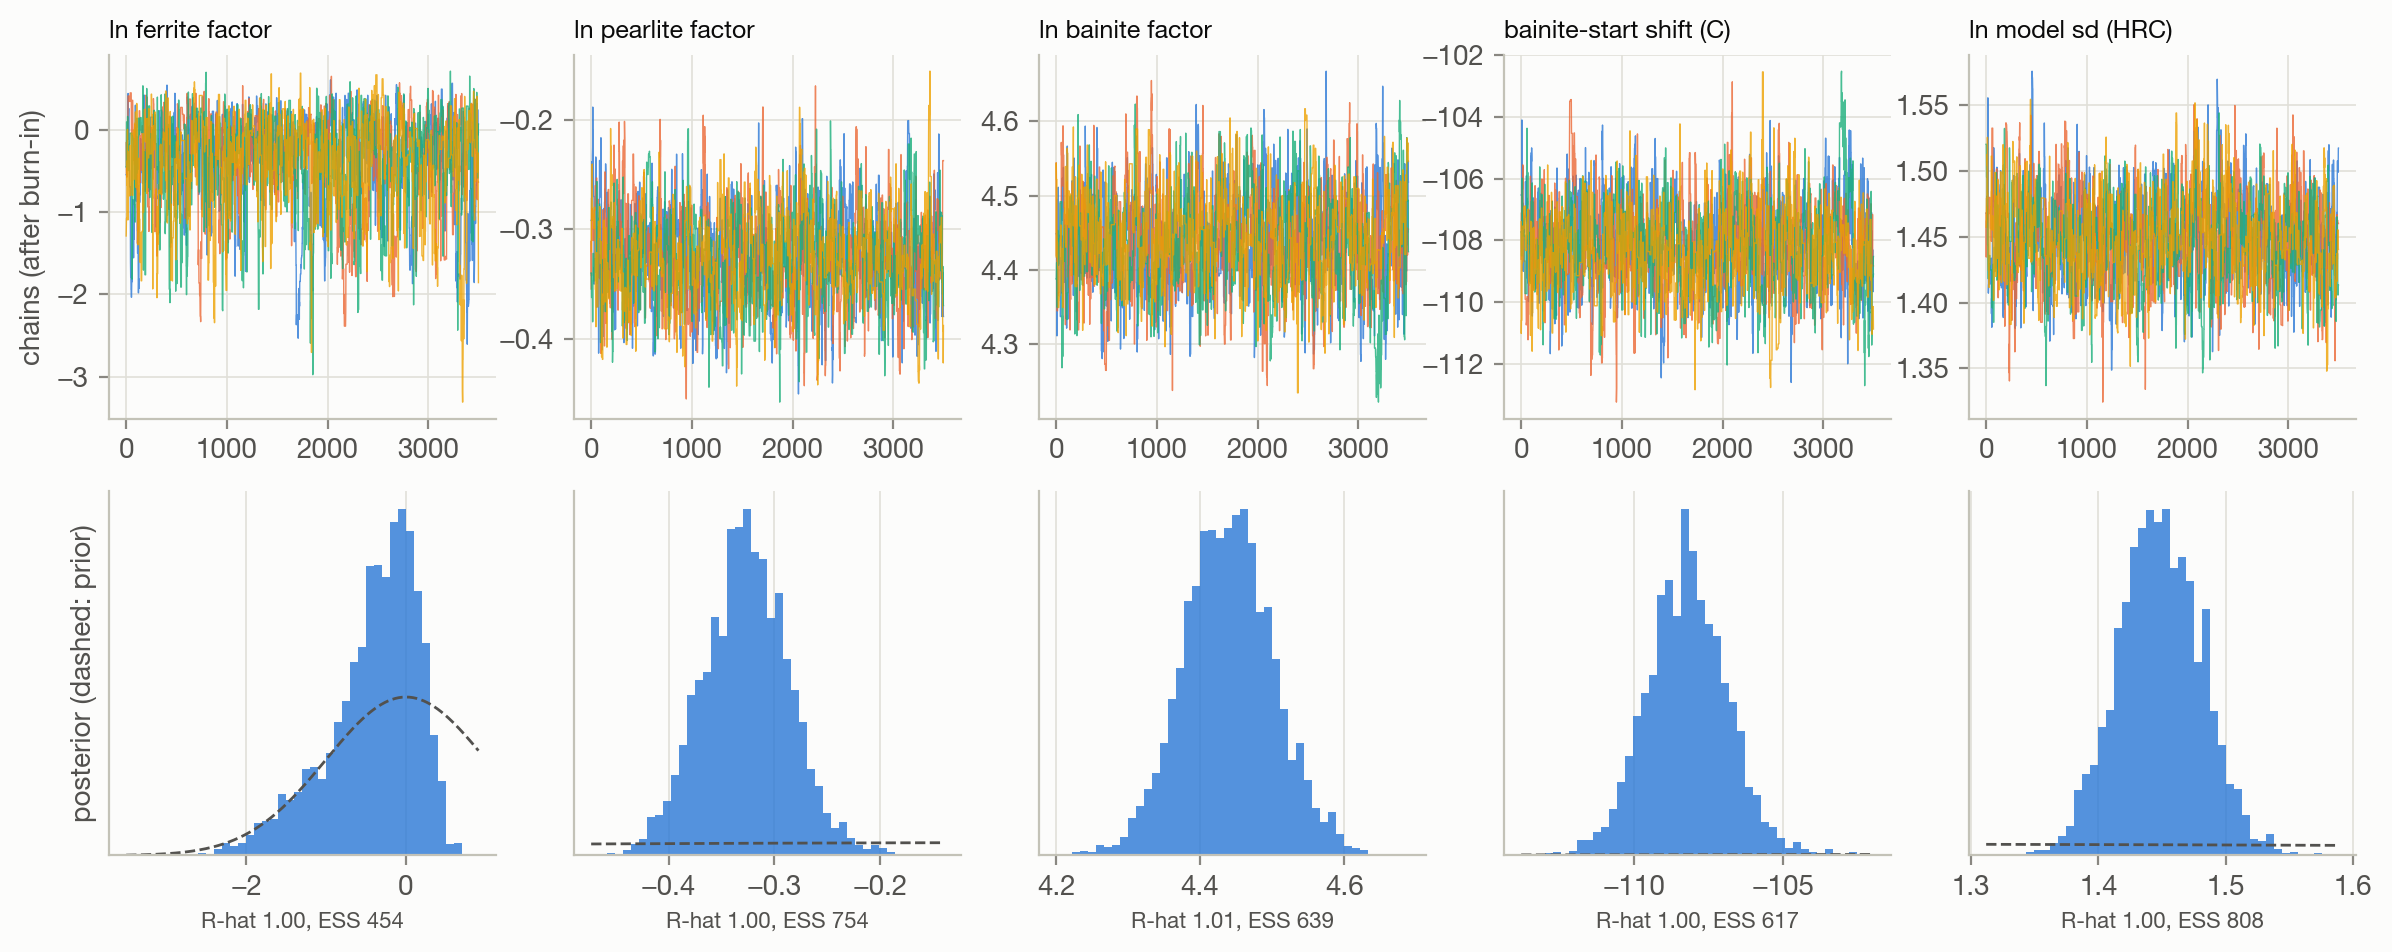

In [5]:
fig("fig40_kinetic_posterior", 1100)

## Propagation and independent coverage
If the parameter uncertainty explained the errors, about 90 % of the measured points would fall inside the
90 % band. They do not: the error is structural (the form of the equations).

In [6]:
pd.read_csv(R / "s11_cct_atlas_coverage.csv").round(3)

,quantity,points,median_band_width,coverage_parametric_90,structural_sd,coverage_with_structural_90,MAE_median_prediction
0,f_FP,423,0,0.598,0.223,0.91,0.106
1,f_B,423,0.01,0.376,0.272,0.896,0.165
2,f_M,423,0,0.331,0.219,0.917,0.121
3,HV,423,1.81,0.05,65.6,0.92,44.3


In [7]:
pd.read_csv(R / "s11_representative_bands.csv").round(3)

,grade,state,quantity,q05,q50,q95
0,1045,furnace cooled,f_bainite,0,0,0
1,1045,furnace cooled,f_martensite,0,0,0
2,1045,furnace cooled,f_ferrite_pearlite,1,1,1
3,1045,air cooled 25 mm,f_bainite,0,0,0
4,1045,air cooled 25 mm,f_martensite,0,0,0
5,1045,air cooled 25 mm,f_ferrite_pearlite,1,1,1
6,1045,"oil quenched 50 mm, mid-radius",f_bainite,0,0,0
7,1045,"oil quenched 50 mm, mid-radius",f_martensite,0,0,0
8,1045,"oil quenched 50 mm, mid-radius",f_ferrite_pearlite,1,1,1
9,4140,furnace cooled,f_bainite,0,0,0


In [8]:
d = pd.read_csv(R / "s11_dilatometry_bands.csv"); print("inside the 90 % band:", round(d.inside.mean(), 2)); d.round(0)

inside the 90 % band: 0.37


,steel,rate,start,measured,q05,q50,q95,share_predicting_start,inside
0,EN3B,0,T_ferrite_start,780,790,798,800,1,False
1,EN3B,0,T_ferrite_start,783,784,794,797,1,False
2,EN3B,0,T_ferrite_start,780,774,787,791,1,True
3,EN3B,1,T_ferrite_start,774,764,781,785,1,True
4,EN3B,2,T_ferrite_start,756,752,773,778,1,True
5,EN3B,5,T_ferrite_start,744,730,759,767,1,True
6,EN3B,10,T_ferrite_start,727,707,745,755,1,True
7,EN3B,20,T_ferrite_start,721,674,727,740,1,True
8,EN3B,20,T_pearlite_start,646,497,562,606,1,False
9,EN3B,50,T_ferrite_start,691,595,693,713,1,True


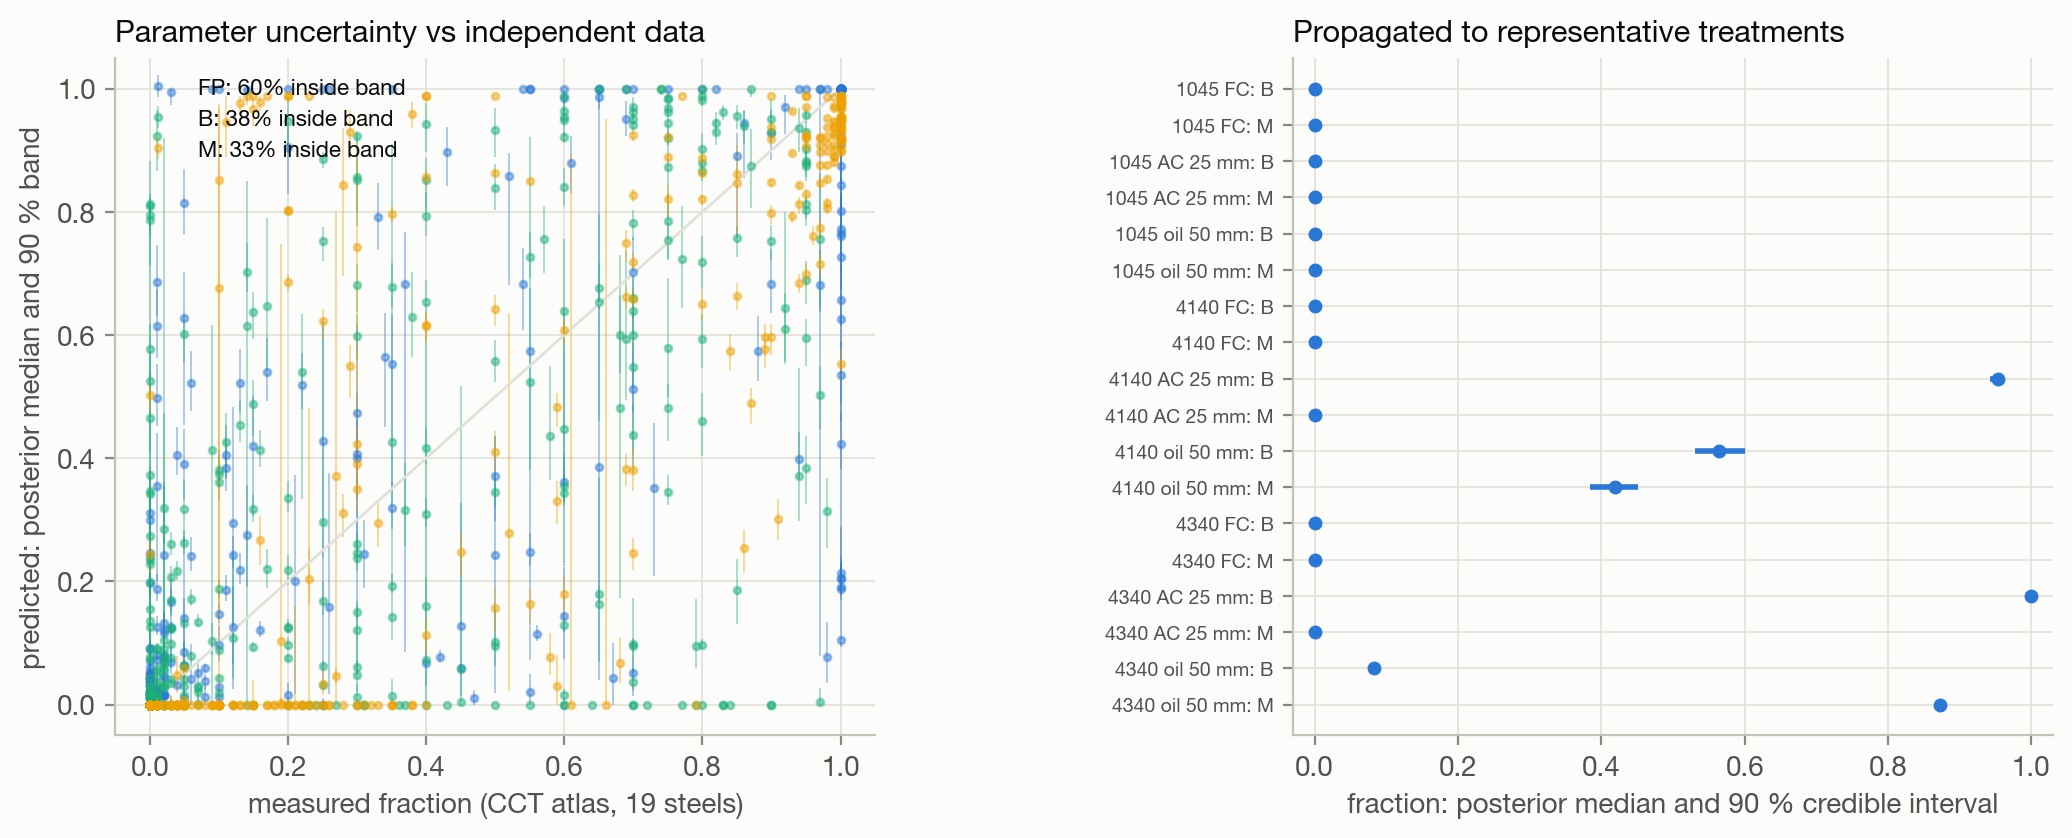

In [9]:
fig("fig41_kinetic_uncertainty_propagation", 1100)